In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("awsaf49/asvpoof-2019-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/awsaf49/asvpoof-2019-dataset


In [2]:
pip install conformer

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import torch
import torchaudio
from torch.utils.data import Dataset
import torch.nn.functional as F

class ASVSpoofDataset(Dataset):
    
    def __init__(self, protocol_file, audio_dir, max_len=64000):
        self.samples = []
        self.audio_dir = audio_dir
        self.max_len = max_len
        
        with open(protocol_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                file_id = parts[1]
                label = parts[-1]

                label = 1 if label == "bonafide" else 0

                path = os.path.join(audio_dir, file_id + ".flac")

                # 🔥 CRITICAL FIX: skip missing files
                if os.path.exists(path):
                    self.samples.append((path, label))

        print(f"✅ Loaded {len(self.samples)} valid samples")

        # 🔥 Pre-create resampler (faster)
        self.resampler = torchaudio.transforms.Resample(orig_freq=16000, new_freq=16000)

    def __len__(self):
        return len(self.samples)

    def load_audio(self, path):

        try:
            audio, sr = torchaudio.load(path)

            # 🔹 convert to mono
            if audio.shape[0] > 1:
                audio = audio.mean(dim=0)
            else:
                audio = audio.squeeze(0)

            # 🔹 resample if needed
            if sr != 16000:
                resampler = torchaudio.transforms.Resample(sr, 16000)
                audio = resampler(audio)

            # 🔹 trim / pad
            if audio.shape[0] > self.max_len:
                audio = audio[:self.max_len]
            else:
                audio = F.pad(audio, (0, self.max_len - audio.shape[0]))

            return audio

        except Exception as e:
            # 🔥 VERY IMPORTANT: avoid crashes
            print(f"⚠️ Skipping file: {path}")
            return torch.zeros(self.max_len)

    def __getitem__(self, idx):
        path, label = self.samples[idx]

        audio = self.load_audio(path)

        return audio, torch.tensor(label, dtype=torch.long)

In [4]:
import torch
import torch.nn as nn
import torchaudio
from conformer import Conformer

class ConformerDetector(nn.Module):

    def __init__(self):
        super().__init__()

        # 🔹 Mel Spectrogram
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=16000,
            n_fft=1024,
            hop_length=160,
            win_length=400,
            n_mels=128   # 👈 better standard
        )

        # 🔹 SpecAugment (VERY IMPORTANT)
        self.freq_mask = torchaudio.transforms.FrequencyMasking(15)
        self.time_mask = torchaudio.transforms.TimeMasking(35)

        # 🔹 Conformer
        self.conformer = Conformer(
            dim=128,
            depth=6,
            heads=4,
            dim_head=32,
            conv_kernel_size=31
        )

        self.dropout = nn.Dropout(0.3)

        self.classifier = nn.Linear(128, 2)

    def forward(self, x):

        # 🔹 Feature extraction
        x = self.mel(x)
        x = torch.log1p(x)

        # 🔹 Normalize (VERY IMPORTANT)
        x = (x - x.mean(dim=-1, keepdim=True)) / (x.std(dim=-1, keepdim=True) + 1e-6)

        # 🔹 Augmentation (only during training)
        if self.training:
            x = self.freq_mask(x)
            x = self.time_mask(x)

        # 🔹 Prepare for Conformer
        x = x.transpose(1, 2)  # [B, T, F]

        x = self.conformer(x)

        # 🔹 Better pooling (important)
        x = torch.max(x, dim=1)[0]

        # 🔹 Regularization
        x = self.dropout(x)

        out = self.classifier(x)

        return out

In [5]:
from torch.utils.data import DataLoader

# 🔹 Train dataset
train_dataset = ASVSpoofDataset(
    protocol_file="/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/PA/PA/ASVspoof2019_PA_cm_protocols/ASVspoof2019.PA.cm.train.trn.txt",
    audio_dir="/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/PA/PA/ASVspoof2019_PA_train/flac"
)

# 🔹 Validation dataset (VERY IMPORTANT)
val_dataset = ASVSpoofDataset(
    protocol_file="/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/PA/PA/ASVspoof2019_PA_cm_protocols/ASVspoof2019.PA.cm.dev.trl.txt",
    audio_dir="/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/PA/PA/ASVspoof2019_PA_dev/flac"
)

# 🔹 DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,        # 👈 safer for Kaggle
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

✅ Loaded 54000 valid samples
✅ Loaded 29700 valid samples


In [6]:
import torch
from tqdm import tqdm

def train_epoch(model, loader, optimizer, criterion, device, scaler):

    model.train()
    total_loss = 0

    loop = tqdm(loader)

    for audio, label in loop:

        audio = audio.to(device, non_blocking=True)
        label = label.to(device, non_blocking=True)

        optimizer.zero_grad()

        # 🔥 Mixed precision (faster + better)
        with torch.amp.autocast(device_type='cuda'):

            output = model(audio)
            loss = criterion(output, label)

        # 🔥 Scaled backward
        scaler.scale(loss).backward()

        # 🔥 Gradient clipping (VERY IMPORTANT for Conformer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

        # 🔥 Show live loss
        loop.set_description(f"Loss: {loss.item():.4f}")

    return total_loss / len(loader)

In [7]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score
import numpy as np
import torch

def evaluate(model, loader, device):

    model.eval()

    preds = []
    labels = []
    scores = []

    with torch.no_grad():

        for audio, label in loader:

            audio = audio.to(device, non_blocking=True)
            label = label.to(device, non_blocking=True)

            out = model(audio)

            prob = torch.softmax(out, dim=1)[:, 1]

            scores.extend(prob.detach().cpu().numpy())
            labels.extend(label.detach().cpu().numpy())

    scores = np.array(scores)
    labels = np.array(labels)

    # 🔹 threshold (can tune later)
    threshold = 0.5
    preds = (scores >= threshold).astype(int)

    # 🔹 metrics
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds)
    precision = precision_score(labels, preds)
    recall = recall_score(labels, preds)
    auc = roc_auc_score(labels, scores)

    return acc, f1, precision, recall, auc, labels, scores, preds

In [8]:
from sklearn.metrics import roc_curve
import numpy as np

def compute_eer(labels, scores):

    fpr, tpr, thresholds = roc_curve(labels, scores)

    fnr = 1 - tpr

    eer = fpr[np.nanargmin(np.absolute((fnr - fpr)))]

    return eer

In [9]:
import os
import torch

os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

device = "cuda" if torch.cuda.is_available() else "cpu"

# ✅ FIXED scaler
scaler = torch.amp.GradScaler()

model = ConformerDetector().to(device)

# 🔥 Loss (handle imbalance)
weights = torch.tensor([1.0, 2.0]).to(device)
criterion = torch.nn.CrossEntropyLoss(weight=weights)

# 🔥 Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-5,
    weight_decay=1e-4
)

# 🔥 Scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=20
)

epochs = 5  # ✅ increased

# 🔥 Store metrics
train_losses = []
val_accs = []
val_f1s = []
val_precisions = []
val_recalls = []
val_aucs = []

# 🔥 Best model tracking
best_f1 = 0
best_labels, best_scores, best_preds = None, None, None

for epoch in range(epochs):

    # 🔹 Train
    loss = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device,
        scaler
    )

    # 🔹 Validate
    acc, f1, precision, recall, auc, labels, scores, preds = evaluate(
        model, val_loader, device
    )

    scheduler.step()

    # 🔹 Store metrics
    train_losses.append(loss)
    val_accs.append(acc)
    val_f1s.append(f1)
    val_precisions.append(precision)
    val_recalls.append(recall)
    val_aucs.append(auc)

    # 🔥 Save best outputs
    if f1 > best_f1:
        best_f1 = f1
        best_labels = labels
        best_scores = scores
        best_preds = preds
        torch.save(model.state_dict(), "best_model.pth")

    print(f"Epoch {epoch+1}: Loss={loss:.4f}, Acc={acc:.4f}, F1={f1:.4f}, AUC={auc:.4f}")

Loss: 0.4417: 100%|██████████| 3375/3375 [17:55<00:00,  3.14it/s]


Epoch 1: Loss=0.3753, Acc=0.8831, F1=0.6139, AUC=0.9228


Loss: 0.3649: 100%|██████████| 3375/3375 [11:38<00:00,  4.83it/s]


Epoch 2: Loss=0.2498, Acc=0.9029, F1=0.6975, AUC=0.9453


Loss: 0.2727: 100%|██████████| 3375/3375 [11:35<00:00,  4.85it/s]


Epoch 3: Loss=0.2260, Acc=0.9037, F1=0.6944, AUC=0.9480


Loss: 0.1210: 100%|██████████| 3375/3375 [11:38<00:00,  4.83it/s]


Epoch 4: Loss=0.2191, Acc=0.8977, F1=0.6397, AUC=0.9527


Loss: 0.0936: 100%|██████████| 3375/3375 [11:51<00:00,  4.74it/s]


Epoch 5: Loss=0.2095, Acc=0.9202, F1=0.7604, AUC=0.9581


In [10]:
test_dataset = ASVSpoofDataset(
    protocol_file="/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/PA/PA/ASVspoof2019_PA_cm_protocols/ASVspoof2019.PA.cm.eval.trl.txt",
    audio_dir="/kaggle/input/datasets/awsaf49/asvpoof-2019-dataset/PA/PA/ASVspoof2019_PA_eval/flac"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,   # ✅ IMPORTANT for Kaggle
    pin_memory=True
)

✅ Loaded 134730 valid samples


In [11]:
test_acc, test_f1, test_precision, test_recall, test_auc, test_labels, test_scores, test_preds = evaluate(
    model, test_loader, device
)

test_eer = compute_eer(test_labels, test_scores)

print("\nTEST RESULTS")
print("Accuracy:", test_acc)
print("F1:", test_f1)
print("AUC:", test_auc)
print("EER:", test_eer)


TEST RESULTS
Accuracy: 0.930609366881912
F1: 0.7274582398040987
AUC: 0.9564145595278447
EER: 0.10799039780521262


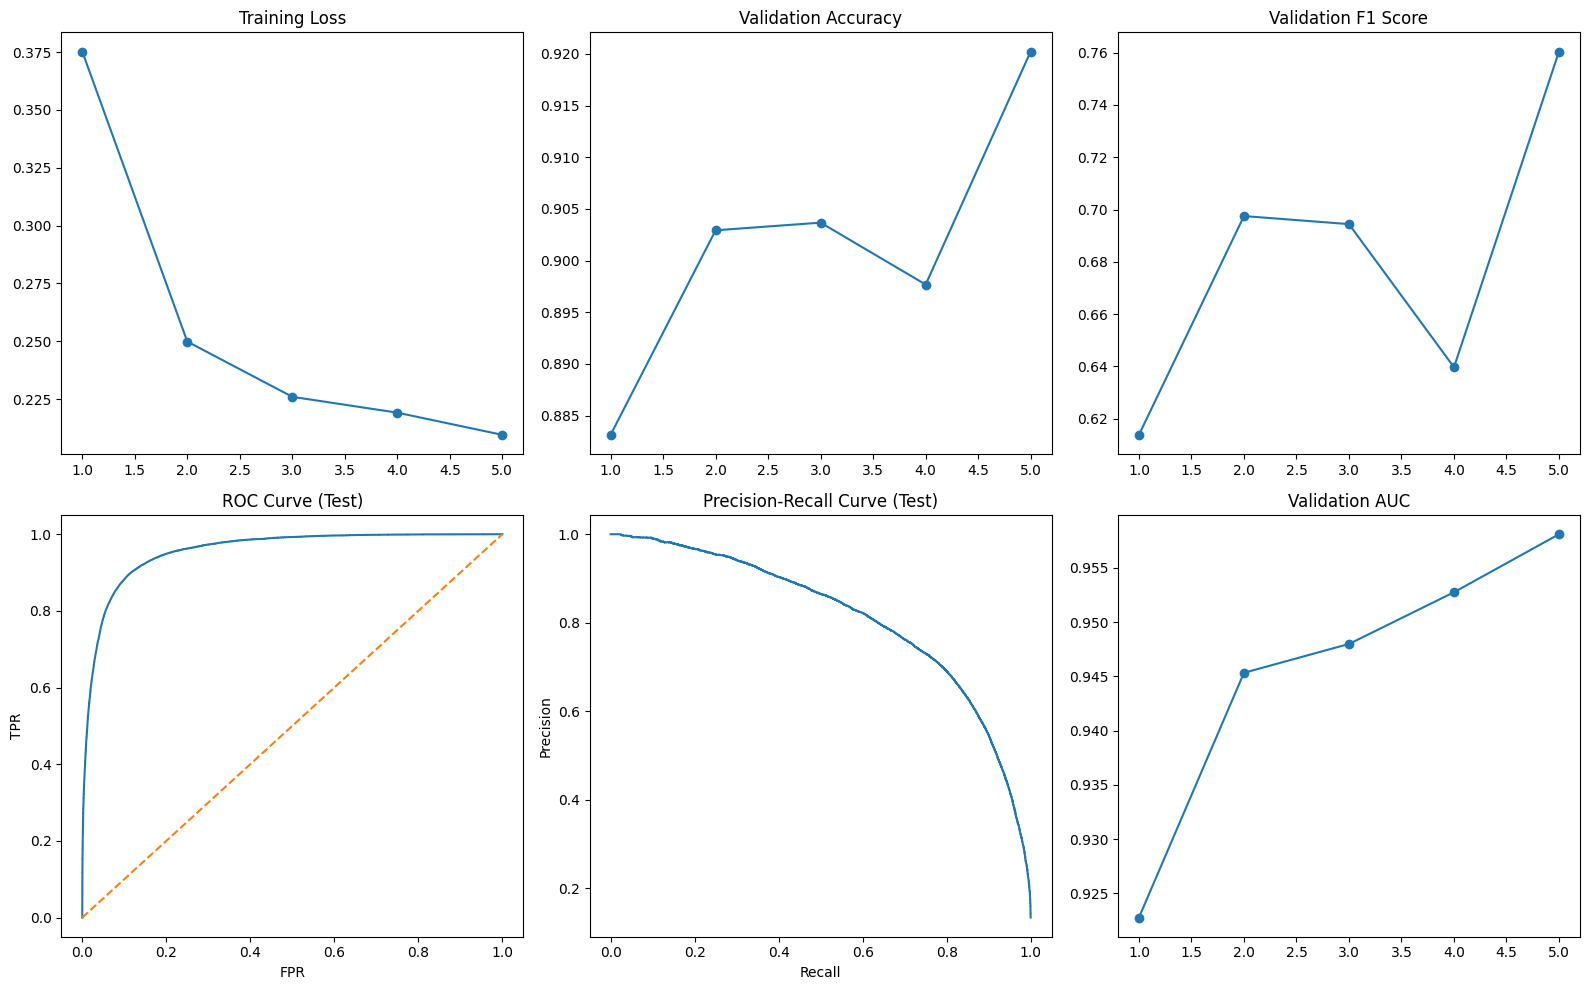

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

epochs_range = range(1, len(train_losses)+1)

plt.figure(figsize=(16,10))

# 🔹 1. Loss
plt.subplot(2,3,1)
plt.plot(epochs_range, train_losses, marker='o')
plt.title("Training Loss")

# 🔹 2. Accuracy
plt.subplot(2,3,2)
plt.plot(epochs_range, val_accs, label="Val Acc", marker='o')
plt.title("Validation Accuracy")

# 🔹 3. F1
plt.subplot(2,3,3)
plt.plot(epochs_range, val_f1s, label="Val F1", marker='o')
plt.title("Validation F1 Score")

# 🔹 4. ROC Curve (TEST)
fpr, tpr, _ = roc_curve(test_labels, test_scores)

plt.subplot(2,3,4)
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'--')
plt.title("ROC Curve (Test)")
plt.xlabel("FPR")
plt.ylabel("TPR")

# 🔹 5. Precision-Recall Curve (TEST)
precision_curve, recall_curve, _ = precision_recall_curve(test_labels, test_scores)

plt.subplot(2,3,5)
plt.plot(recall_curve, precision_curve)
plt.title("Precision-Recall Curve (Test)")
plt.xlabel("Recall")
plt.ylabel("Precision")

# 🔹 6. AUC over epochs
plt.subplot(2,3,6)
plt.plot(epochs_range, val_aucs, marker='o')
plt.title("Validation AUC")

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

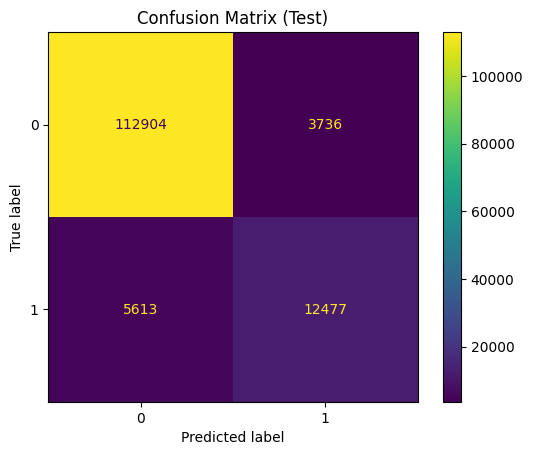

In [13]:
cm = confusion_matrix(test_labels, test_preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

plt.figure()
disp.plot()
plt.title("Confusion Matrix (Test)")
plt.show()

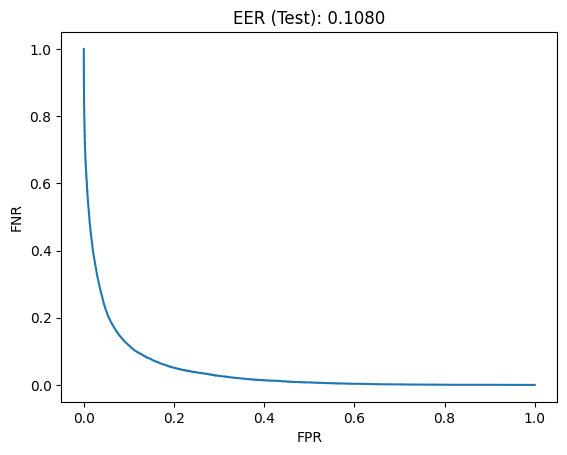

In [14]:
plt.figure()
plt.title(f"EER (Test): {test_eer:.4f}")
plt.plot(fpr, 1 - tpr)
plt.xlabel("FPR")
plt.ylabel("FNR")
plt.show()